# Etapy budowy kampusów data center w USA

Szereg czasowy **Sentinel-2 L2A** z Microsoft Planetary Computer, kompozyty
półroczne 2018–2025, klasyfikacja pokrycia terenu i maszyna etapów.

Pięć etapów, w kolejności procesu budowy:

| etap | nazwa | po czym rozpoznany |
|---|---|---|
| 0 | PRZED BUDOWĄ | nie spełnia warunków etapu 1+ |
| 1 | ROBOTY ZIEMNE | przyrost gołego gruntu względem **własnego** poziomu wyjściowego obszaru |
| 2 | ZABUDOWA ROŚNIE | zabudowa potwierdzona ≥ 15% celu kampusu |
| 3 | BRYŁA ZAMKNIĘTA | zabudowa potwierdzona ≥ 65% celu kampusu |
| 4 | ZIELEŃ URZĄDZONA | bryła zamknięta + **powrót** zieleni w kołnierzu wokół hal |

Notatnik tylko **rysuje** to, co policzył `run.py` (`out/maps/*.npz`,
`out/*.csv`, `out/model.joblib`). Nie trenuje modelu od nowa, więc pokazuje
dokładnie te liczby, które poszły do raportu.

In [1]:
import json, os, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config as C, labels as L, stages as S, viz, plot

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight",
                     "axes.titlesize": 10, "font.size": 9})

df  = pd.read_csv(os.path.join(C.OUT_DIR, "etapy.csv"))
dfl = pd.read_csv(os.path.join(C.OUT_DIR, "przebieg.csv"))
EPOCHS = sorted(dfl.epoch.unique())
print(f"obszarów: {len(df)}   epok: {len(EPOCHS)}   ({EPOCHS[0]} .. {EPOCHS[-1]})")

obszarów: 10   epok: 16   (2018H1 .. 2025H2)


---
## 1. Skąd się wzięła lista dziesięciu obszarów

Nie z pamięci — z pomiaru. `discover.py` pobiera z OpenStreetMap wszystkie
obiekty otagowane `telecom=data_center` / `building=data_center` (w CONUS:
**1730 hal**), skupia je w kampusy i wybiera dziesięć największych
po **powierzchni hal**.

To jest ranking **mierzalny**, a nie ranking po nakładach — tego drugiego nie
mam skąd wziąć w sposób weryfikowalny.

Dlaczego to ma znaczenie: pierwsza wersja listy miała dla Ashburn punkt
`39.0437, -77.4875`. W kwadracie o półboku 1,5 km wokół niego jest **0,0% hal**
(zabudowa zajmuje 9,8%, ale to domy jednorodzinne). Punkt leżał w dzielnicy
mieszkaniowej, kilka kilometrów od Data Center Alley — a potok policzył wtedy
*„PRZED BUDOWĄ, zabudowa 1,6%"* dla najgęstszego skupiska data center na
świecie. Wynik był poprawny dla złego kadru.

In [2]:
meta = json.load(open("sites.json", encoding="utf-8"))
print(f"sites.json wygenerowany {meta['generated']}  ·  {meta['ranking']}")

s = pd.DataFrame(meta["sites"])
s["pow_ha"] = s.hall_area_m2 / 1e4
s["cel_%"]  = s.target_built_frac * 100
if "place" not in s.columns:
    s["place"] = "?"
show = s[["id", "place", "halls", "pow_ha", "cel_%", "radius_m",
          "under_constr", "lat", "lon"]]
show.columns = ["obszar", "gdzie", "hal", "pow. hal [ha]", "cel [%AOI]",
                "R [m]", "w budowie", "lat", "lon"]
show.round(2)

sites.json wygenerowany 2026-10-02  ·  powierzchnia hal zmapowanych w OSM (NIE nakłady)


,obszar,gdzie,hal,pow. hal [ha],cel [%AOI],R [m],w budowie,lat,lon
0,amazon_web_services_3900,"Loudoun County, Virginia",140,188.61,7.54,2500,10,39.01,-77.46
1,google_4006,"New Albany, Ohio",17,45.24,3.63,1766,0,40.06,-82.76
2,quality_technology_services_3748,"Henrico County, Virginia",17,43.10,3.63,1723,6,37.48,-77.24
3,bez_nazwy_3250,"Taylor County, Texas",40,35.98,4.93,1351,0,32.50,-99.78
4,meta_4429,"Crook County, Oregon",11,35.17,3.36,1619,0,44.29,-120.88
5,meta_4166,"Altoona, Iowa",7,30.94,5.50,1185,0,41.67,-93.51
6,meta_4112,"Papillion, Nebraska",9,30.80,1.98,1972,0,41.13,-96.15
7,meta_3482,"Valencia County, New Mexico",5,29.11,9.49,875,0,34.83,-106.78
8,stack_infrastructure_4555,"Hillsboro, Oregon",20,27.70,1.86,1927,1,45.56,-122.93
9,google_4117,"Council Bluffs, Iowa",16,26.79,4.28,1251,0,41.18,-95.80


`cel [%AOI]` to powierzchnia hal z OSM podzielona przez powierzchnię kadru.
Potok porównuje do niej udział zabudowy potwierdzonej z Sentinela — dzięki temu
nie trzeba jednego progu dla kampusu gęstego i rozrzuconego.

**Cel liczymy wyłącznie z obiektów mających tag `building`.** `telecom=data_center`
bywa w OSM przypięty do granicy terenu, nie do hali: na kampusie Google w Berkeley
County jeden taki obiekt ma 77,2 ha (`landuse=industrial`, bez tagu `building`),
podczas gdy wszystkie rzeczywiste hale razem — 19,7 ha. Liczenie działki jako hali
zawyżało cel pięciokrotnie i czyniło próg „bryła zamknięta" nieosiągalnym.

Kolumna `gdzie` pochodzi z geokodowania wstecznego współrzędnych (Nominatim).
Część kampusów nie ma w OSM ani `name`, ani `operator` — skupisko 40 hal
w Taylor County w Teksasie nie ma ich w żadnym z 40 obiektów. Operatora
musiałbym w takim wypadku zmyślić, więc go tam nie ma; położenie natomiast
wynika ze współrzędnych i jest sprawdzalne.

---
## 2. Wszystkie obszary: „przed" i „teraz"

Barwy naturalne Sentinela. To mapa poglądowa całego zadania — jednym spojrzeniem
widać, które obszary się zmieniły, **niezależnie od tego, co orzekł model**.
Jeśli górny i dolny obrazek są identyczne, a potok mówi „BRYŁA ZAMKNIĘTA", to
znaczy, że kampus stał już w 2018.

In [3]:
sites = [sd for sd in C.SITES if sd["id"] in set(df.id)]
fig = viz.overview(sites, EPOCHS[0], EPOCHS[-1], ncols=5)
plt.show()

---
## 3. Mapa etapów: kto kiedy w który etap wszedł

Wiersz = obszar, kolumna = epoka, kolor = etap. Przebieg jest **niemalejący** —
budowa się nie cofa, a jedna epoka z chmurami bez tej zapadki wyrzucałaby obszar
z etapu 3 na 1.

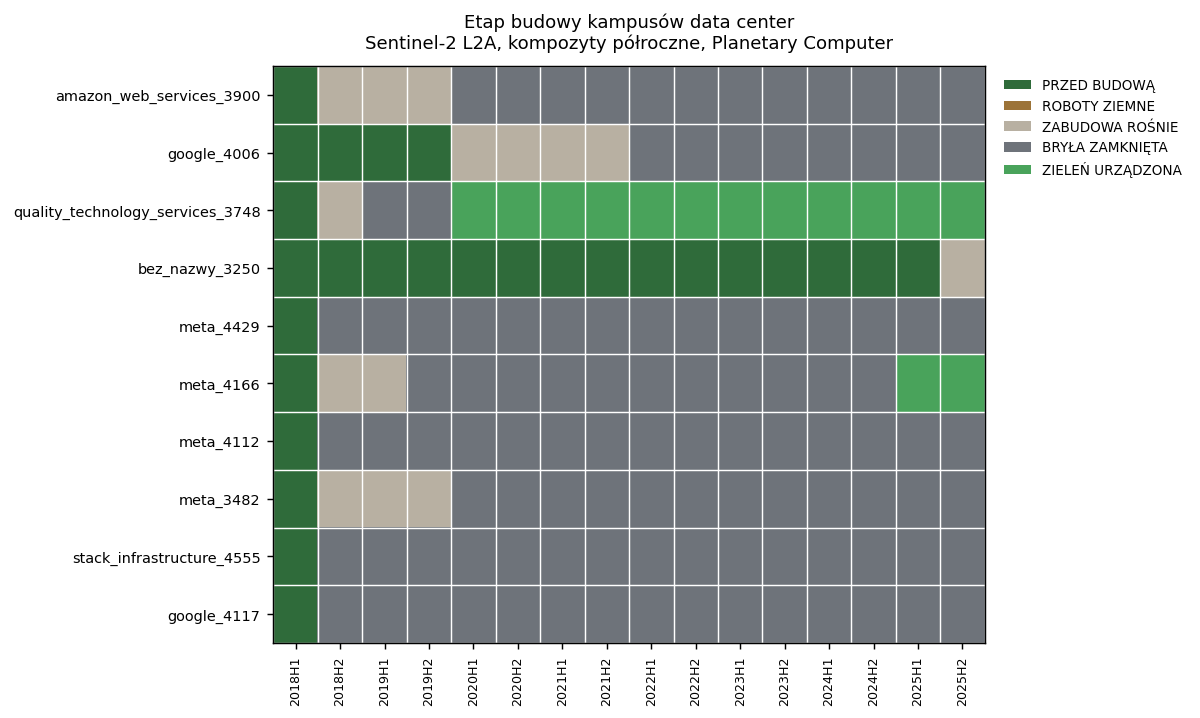

In [4]:
plot.timeline(dfl, os.path.join(C.OUT_DIR, "etapy.png"))
from IPython.display import Image, display
display(Image(os.path.join(C.OUT_DIR, "etapy.png")))

---
## 4. Na jakim etapie jest która inwestycja

`postęp` = zabudowa potwierdzona / cel z OSM. Mówi więcej niż sam udział
zabudowy, bo uwzględnia, jak gęsty jest dany kampus.

**Jak czytać postęp znacznie powyżej 100%.** Mianownikiem jest powierzchnia hal
zmapowanych w OSM, a nie rzeczywista powierzchnia kampusu. Postęp rzędu 150–200%
znaczy więc jedno z dwóch i trzeba to rozstrzygnąć, a nie zgadywać:

* **OSM jest niekompletny** — stoją hale, których nikt nie zmapował. Wtedy etap
  jest poprawny, a zaniżony jest cel.
* **Potok przesadza** — bierze jasny grunt za dach. Dotyczy zwłaszcza obszarów
  suchych, gdzie goła ziemia jest jasna, a pomyłka GRUNT → DACH wynosi 10,5%.

Rozstrzyga to **sekcja 7b**: jeśli celność (udział potwierdzonej zabudowy
leżącej pod obrysem budynku) jest wysoka, to po prostu brakuje obrysów w OSM;
jeśli niska — potok dolicza grunt. Z tego samego powodu kolumna `cel` jest
w tabeli obok `postępu`: bez niej postęp jest liczbą bez mianownika.

In [5]:
t = df.copy()
t["etap"] = t.stage.map(S.STAGE_SHORT)
t["postęp [%]"] = (t.progress * 100).round(0)
t["zabudowa [%]"] = (t.built_frac * 100).round(1)
t["cel [%]"] = (t.target_built_frac * 100).round(1)
t["grunt [%]"] = (t.bare_frac * 100).round(1)
t["zieleń [%]"] = (t.veg_frac * 100).round(1)
t["kołnierz [%]"] = (t.collar_green * 100).round(0)
gdzie = {x["id"]: x.get("place", "?") for x in C.SITES}
t["gdzie"] = t.id.map(gdzie)
cols = ["id", "gdzie", "etap", "since", "postęp [%]", "zabudowa [%]", "cel [%]",
        "grunt [%]", "zieleń [%]", "kołnierz [%]"]
t[cols].rename(columns={"id": "obszar", "since": "od"}) \
    .sort_values("etap", ascending=False)

,obszar,gdzie,etap,od,postęp [%],zabudowa [%],cel [%],grunt [%],zieleń [%],kołnierz [%]
0,meta_4166,"Altoona, Iowa",4/zieleń,2025H1,336.0,18.5,5.5,29.5,36.7,41.0
1,quality_technology_services_3748,"Henrico County, Virginia",4/zieleń,2020H1,160.0,5.8,3.6,11.1,72.3,45.0
2,google_4006,"New Albany, Ohio",3/zamknięta,2022H1,230.0,8.4,3.6,23.8,53.3,32.0
3,amazon_web_services_3900,"Loudoun County, Virginia",3/zamknięta,2020H1,120.0,9.1,7.5,21.6,42.9,32.0
4,meta_4429,"Crook County, Oregon",3/zamknięta,2018H2,202.0,6.8,3.4,25.7,6.4,3.0
5,meta_4112,"Papillion, Nebraska",3/zamknięta,2018H2,672.0,13.3,2.0,37.0,26.2,38.0
6,stack_infrastructure_4555,"Hillsboro, Oregon",3/zamknięta,2018H2,484.0,9.0,1.9,21.3,47.4,41.0
7,meta_3482,"Valencia County, New Mexico",3/zamknięta,2020H1,196.0,18.6,9.5,61.2,0.0,0.0
8,google_4117,"Council Bluffs, Iowa",3/zamknięta,2018H2,265.0,11.3,4.3,36.0,32.3,25.0
9,bez_nazwy_3250,"Taylor County, Texas",2/rośnie,2025H2,16.0,0.8,4.9,71.0,1.8,0.0


### Daty wejścia w kolejne etapy

In [6]:
d = df[["id", "t_earthworks", "t_structures", "t_mature", "t_green"]].copy()
d.columns = ["obszar", "roboty ziemne", "zabudowa rośnie",
             "bryła zamknięta", "zieleń urządzona"]
d.fillna("—")

,obszar,roboty ziemne,zabudowa rośnie,bryła zamknięta,zieleń urządzona
0,meta_4166,2018H2,2018H2,2019H2,2025H1
1,quality_technology_services_3748,2018H2,2018H2,2019H1,2020H1
2,google_4006,2020H1,2020H1,2022H1,—
3,amazon_web_services_3900,2018H2,2018H2,2020H1,—
4,meta_4429,2018H2,2018H2,2018H2,—
5,meta_4112,2018H2,2018H2,2018H2,—
6,stack_infrastructure_4555,2018H2,2018H2,2018H2,—
7,meta_3482,2018H2,2018H2,2020H1,—
8,google_4117,2018H2,2018H2,2018H2,—
9,bez_nazwy_3250,2025H2,2025H2,—,—


---
## 5. Każdy obszar osobno

Dla każdego obszaru cztery rzeczy:

1. **barwy naturalne** przez wszystkie epoki — co widać gołym okiem,
2. **klasyfikacja** przez wszystkie epoki — co z tego zrobił model,
3. **mapa „kiedy pojawiła się zabudowa"** — kolor mówi, w której epoce
   dana hala została potwierdzona,
4. **krzywe** udziałów klas + schodki etapu.

Punkt 4 jest najważniejszy do oceny wiarygodności: widać po nim, czy etap
wynika z wyraźnej zmiany w danych, czy z ledwie przekroczonego progu.

In [7]:
from IPython.display import Markdown, display

def pokaz(site_id):
    sd = next(x for x in C.SITES if x["id"] == site_id)
    r = df[df.id == site_id].iloc[0]
    display(Markdown(
        f"### {site_id} — {sd.get('place', '?')}\n"
        f"**{sd['name']}**  ·  `{sd['lat']:.4f}, {sd['lon']:.4f}`  ·  "
        f"R = {sd['radius_m']} m  ·  cel {sd.get('target_built_frac', 0)*100:.1f}% AOI\n\n"
        f"Stan na {r.epoch_last}: **{r.stage_name}** (od {r.since})  ·  "
        f"zabudowa {r.built_frac*100:.1f}% = {r.progress*100:.0f}% celu  ·  "
        f"grunt {r.bare_frac*100:.1f}%"))

    viz.strip(sd, EPOCHS, kind="rgb", title="barwy naturalne")
    plt.show()
    viz.strip(sd, EPOCHS, kind="cls", title="klasyfikacja i etap")
    plt.show()
    viz.built_growth(sd)
    plt.show()
    plot.site_curves(dfl, site_id, os.path.join(C.OUT_DIR, "krzywe", f"{site_id}.png"))
    display(Image(os.path.join(C.OUT_DIR, "krzywe", f"{site_id}.png")))

### meta_4166 — Altoona, Iowa
**Meta — 7 hal, 31 ha**  ·  `41.6696, -93.5112`  ·  R = 1185 m  ·  cel 5.5% AOI

Stan na 2025H2: **ZIELEŃ URZĄDZONA** (od 2025H1)  ·  zabudowa 18.5% = 336% celu  ·  grunt 29.5%

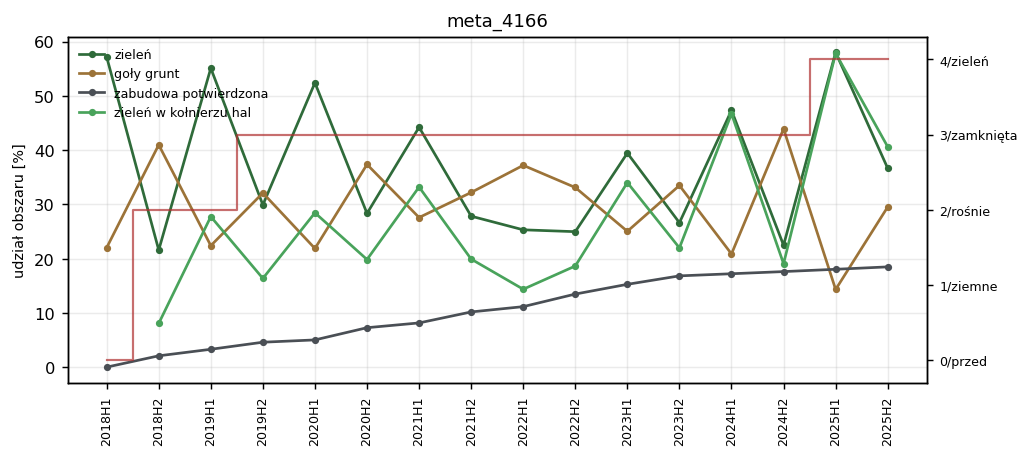

In [8]:
IDS = list(df.sort_values("stage", ascending=False).id)
pokaz(IDS[0])

### quality_technology_services_3748 — Henrico County, Virginia
**Quality Technology Services — 17 hal, 43 ha**  ·  `37.4833, -77.2440`  ·  R = 1723 m  ·  cel 3.6% AOI

Stan na 2025H2: **ZIELEŃ URZĄDZONA** (od 2020H1)  ·  zabudowa 5.8% = 160% celu  ·  grunt 11.1%

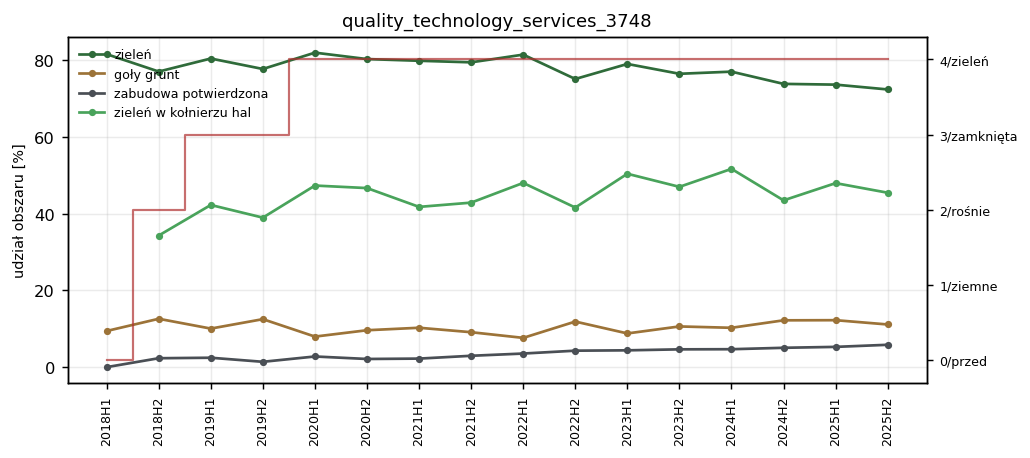

### google_4006 — New Albany, Ohio
**Google — 17 hal, 45 ha**  ·  `40.0600, -82.7584`  ·  R = 1766 m  ·  cel 3.6% AOI

Stan na 2025H2: **BRYŁA ZAMKNIĘTA** (od 2022H1)  ·  zabudowa 8.4% = 230% celu  ·  grunt 23.8%

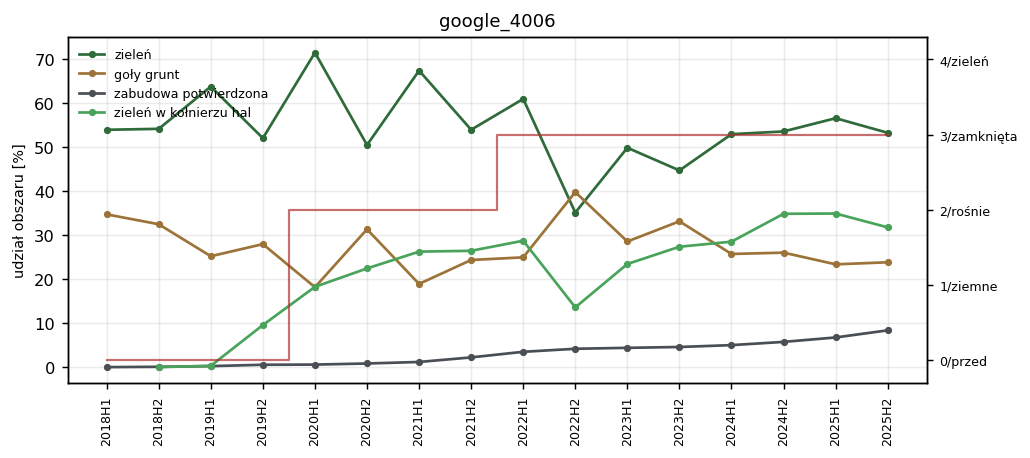

### amazon_web_services_3900 — Loudoun County, Virginia
**Amazon Web Services — 140 hal, 189 ha**  ·  `39.0052, -77.4554`  ·  R = 2500 m  ·  cel 7.5% AOI

Stan na 2025H2: **BRYŁA ZAMKNIĘTA** (od 2020H1)  ·  zabudowa 9.1% = 120% celu  ·  grunt 21.6%

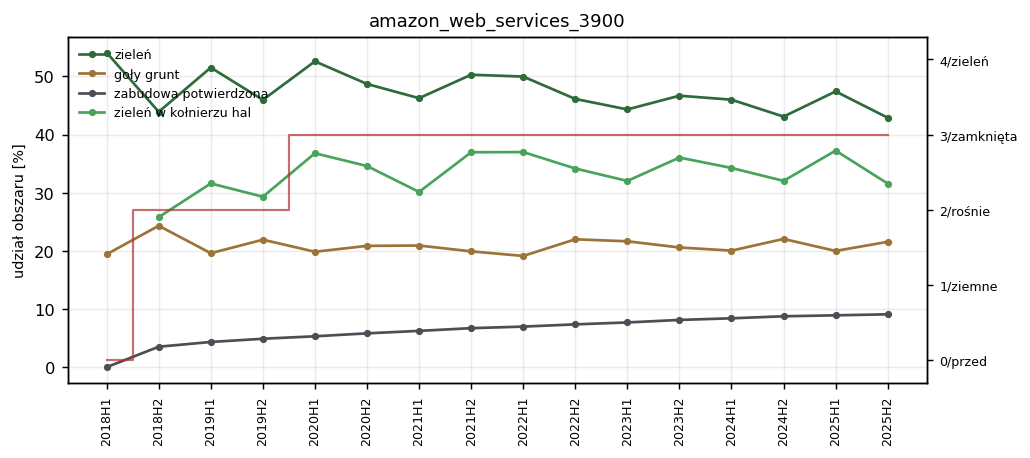

### meta_4429 — Crook County, Oregon
**Meta — 11 hal, 35 ha**  ·  `44.2943, -120.8815`  ·  R = 1619 m  ·  cel 3.4% AOI

Stan na 2025H2: **BRYŁA ZAMKNIĘTA** (od 2018H2)  ·  zabudowa 6.8% = 202% celu  ·  grunt 25.7%

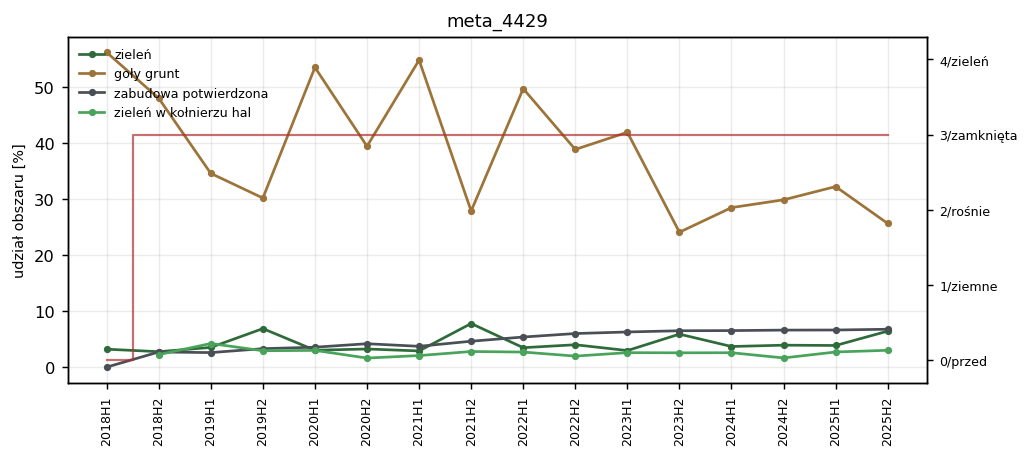

### meta_4112 — Papillion, Nebraska
**Meta — 9 hal, 31 ha**  ·  `41.1268, -96.1463`  ·  R = 1972 m  ·  cel 2.0% AOI

Stan na 2025H2: **BRYŁA ZAMKNIĘTA** (od 2018H2)  ·  zabudowa 13.3% = 672% celu  ·  grunt 37.0%

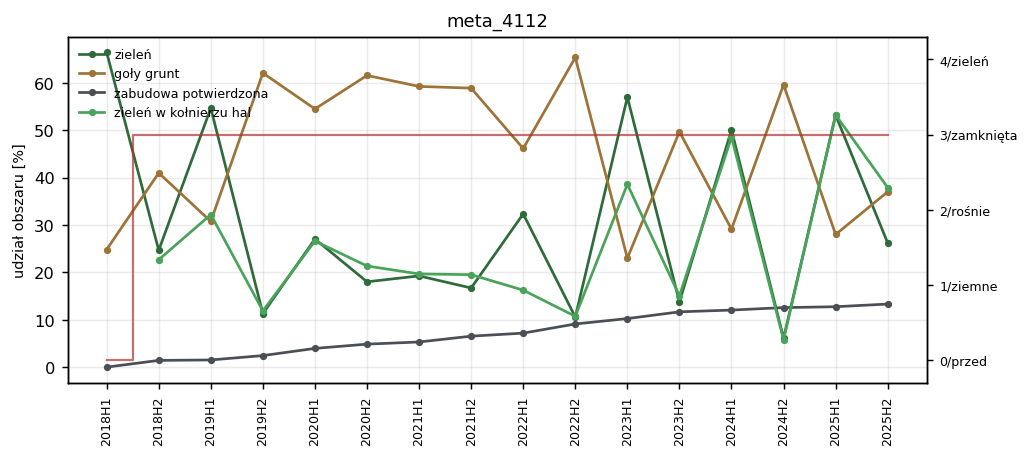

### stack_infrastructure_4555 — Hillsboro, Oregon
**Stack Infrastructure — 20 hal, 28 ha**  ·  `45.5551, -122.9343`  ·  R = 1927 m  ·  cel 1.9% AOI

Stan na 2025H2: **BRYŁA ZAMKNIĘTA** (od 2018H2)  ·  zabudowa 9.0% = 484% celu  ·  grunt 21.3%

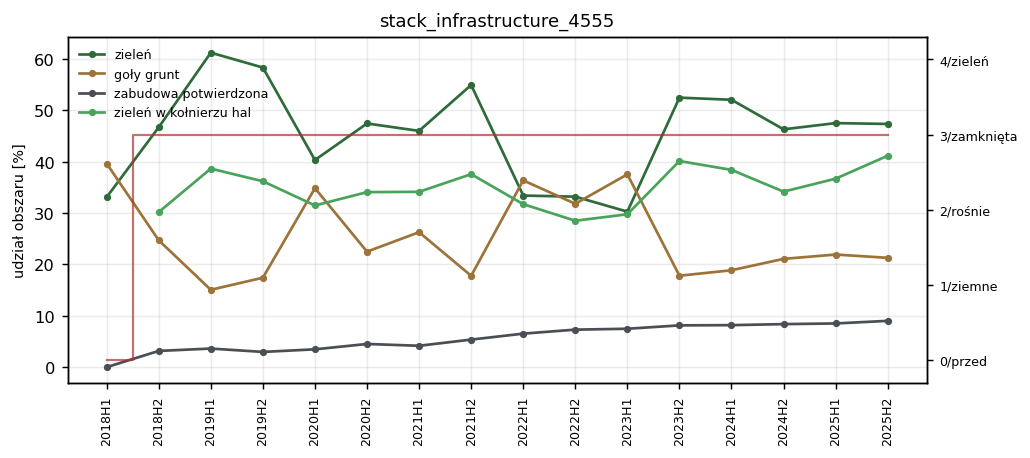

### meta_3482 — Valencia County, New Mexico
**Meta — 5 hal, 29 ha**  ·  `34.8284, -106.7804`  ·  R = 875 m  ·  cel 9.5% AOI

Stan na 2025H2: **BRYŁA ZAMKNIĘTA** (od 2020H1)  ·  zabudowa 18.6% = 196% celu  ·  grunt 61.2%

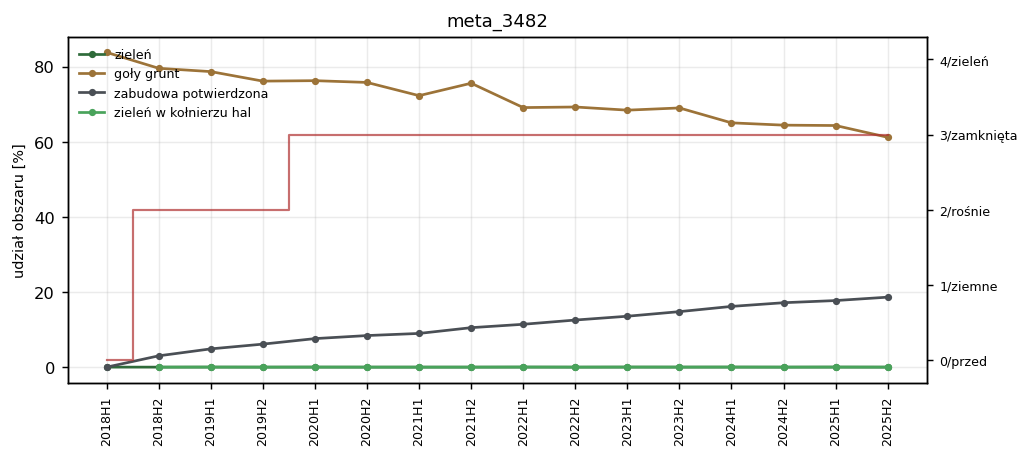

### google_4117 — Council Bluffs, Iowa
**Google — 16 hal, 27 ha**  ·  `41.1752, -95.8017`  ·  R = 1251 m  ·  cel 4.3% AOI

Stan na 2025H2: **BRYŁA ZAMKNIĘTA** (od 2018H2)  ·  zabudowa 11.3% = 265% celu  ·  grunt 36.0%

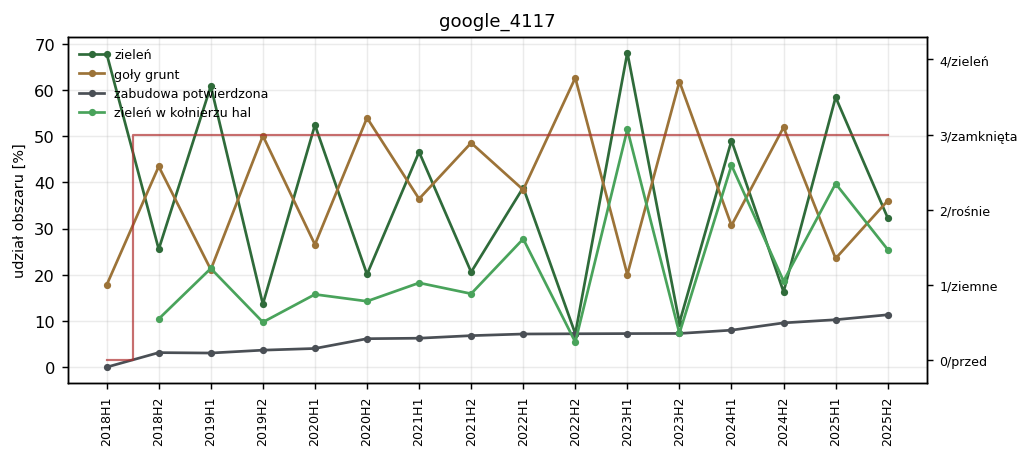

### bez_nazwy_3250 — Taylor County, Texas
**(bez nazwy) — 40 hal, 36 ha**  ·  `32.5002, -99.7840`  ·  R = 1351 m  ·  cel 4.9% AOI

Stan na 2025H2: **ZABUDOWA ROŚNIE** (od 2025H2)  ·  zabudowa 0.8% = 16% celu  ·  grunt 71.0%

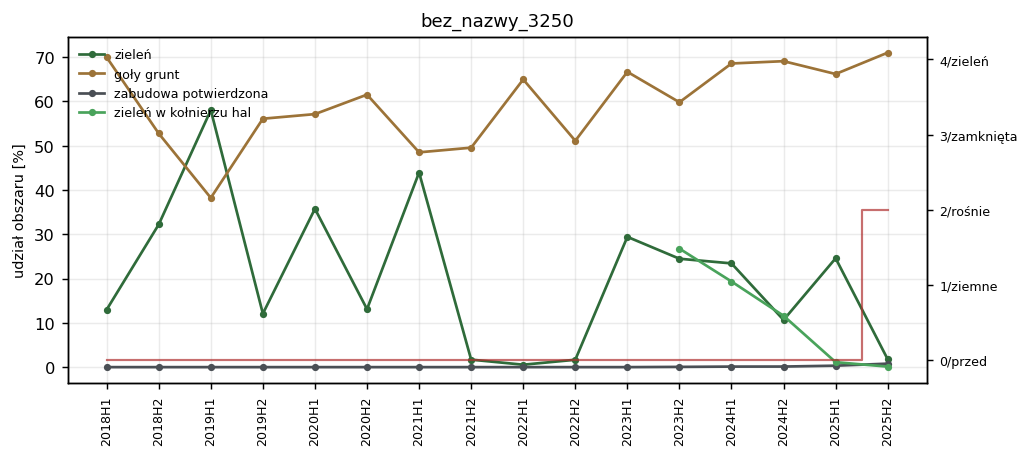

In [9]:
for sid in IDS[1:]:
    pokaz(sid)

---
## 6. Zieleń urządzona — dowód, nie założenie

Ostatni etap budowy to zieleń wokół hal. Ale **przed** budową cały obszar też
jest zielony — pole albo las. Sama obecność zieleni nie odróżnia trawnika od
nietkniętej łąki; odróżnia je **powrót**: zieleń musi najpierw zniknąć (plac
budowy, składowisko, droga technologiczna), a potem wrócić.

Dlatego mierzymy ją w **kołnierzu wokół potwierdzonej zabudowy** (dylatacja
maski hal o 120 m), a nie w pierścieniu o stałym promieniu — i wymagamy
przyrostu względem minimum, jakie ten kołnierz osiągnął w czasie budowy.

In [10]:
for sid in IDS[:3]:
    sd = next(x for x in C.SITES if x["id"] == sid)
    try:
        viz.collar_view(sd)
        plt.show()
    except Exception as e:
        print(f"{sid}: {type(e).__name__}: {e}")

---
## 7. Ile wart jest klasyfikator

Model: las losowy na cechach spektralnych, uczony **raz** na próbkach ze
wszystkich obszarów — jeden model dla wszystkich, żeby „udział zabudowy 25%"
znaczył to samo na każdym kampusie.

Pola treningowe pochodzą z danych publicznych: **ESA WorldCover 10 m** (klasy
pokrycia) i **OSM** (obrysy budynków i nawierzchni), pobierane z kadru 2×
szerszego **z wyłączeniem samego obszaru inwestycji** — inaczej model uczyłby
się stanu kampusu z 2021 i potem „rozpoznawał" to, co już widział.

In [11]:
import joblib
m = joblib.load(os.path.join(C.OUT_DIR, "model.joblib"))
rep = m["report"]
print(f"próbek treningowych: {rep['n_train']}   sprawdzających: {rep['n_test']}")
print("liczebność klas:", rep["counts"])
viz.confusion(rep)
plt.show()
viz.importances(rep)
plt.show()
print(f"\nGRUNT wzięty za DACH: {rep.get('bare_as_roof', float('nan'))*100:.1f}%")

próbek treningowych: 74001   sprawdzających: 24667
liczebność klas: {'ZIELEŃ': 22675, 'GRUNT': 22995, 'DACH': 20253, 'ASFALT': 24321, 'WODA': 8424}



GRUNT wzięty za DACH: 10.5%


Cała pomyłka siedzi między **GRUNT / DACH / ASFALT** — zieleń i woda są
rozdzielane bezbłędnie. To jest oczekiwane i nieusuwalne spektralnie: świeży
jasny beton, blacha i przesuszona jasna glina mają w sześciu pasmach Sentinela
podpisy, które na siebie zachodzą.

Dlatego **zabudowa nie jest brana z jednej klasyfikacji**. Piksel wchodzi do
zabudowy po trzech filtrach, z których żaden nie jest spektralny:

1. **pewność** — `p(DACH) ≥ 0.60`; fałszywy alarm jest tu gorszy niż spóźnienie
   o jedną epokę,
2. **spójność przestrzenna** — skupisko ≥ 25 pikseli (0,25 ha); hala ma
   100–500 pikseli, pojedynczy jasny piksel to szum,
3. **trwałość w czasie** — i to jest filtr rozstrzygający:
   **jasna glina wysycha i moknie, budynek nie znika.** Klasa DACH musi się
   utrzymać w dwóch kolejnych epokach, i od tego momentu piksel pozostaje
   zabudową.

Poniżej widać, ile ten filtr zdejmuje: `roof_raw` to surowa klasa DACH z jednej
epoki, `built` to zabudowa potwierdzona.

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
for sid in IDS:
    d = dfl[dfl.id == sid].sort_values("epoch")
    ax.plot(d.epoch, (d.roof_raw - d.built) * 100, marker="o", ms=2.5,
            lw=1, alpha=0.75, label=sid[:22])
ax.set_ylabel("roof_raw − built  [punkty proc. AOI]")
ax.set_title("Ile zdejmują filtry ostrożności (surowa klasa DACH minus zabudowa potwierdzona)")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.grid(alpha=0.3)
ax.axhline(0, color="k", lw=0.6)
ax.legend(fontsize=6.5, ncol=2, frameon=False)
plt.show()

---
## 7b. Kontrola niezależna: czy „zabudowa potwierdzona" to naprawdę budynki

Potok sam o sobie mówi, że zabudowa jest „potwierdzona". To twierdzenie trzeba
sprawdzić czymś **spoza potoku** — a mamy czym: obrysami budynków z OSM, których
klasyfikator dla tego obszaru nie widział (pola treningowe pochodzą z otoczenia,
z wyłączeniem samego kampusu).

Jest to potrzebne właśnie tutaj, bo pomyłka **GRUNT → DACH wynosi 10,5%** w
pojedynczej klasyfikacji, a **zapadka** sprawia, że raz potwierdzona zabudowa już
nie znika. Fałszywie potwierdzony płat suchej, jasnej gliny zostałby w wyniku na
zawsze.

* **celność** — ile z potwierdzonej zabudowy leży pod obrysem budynku.
  Niska celność = potok bierze grunt za dach.
* **pokrycie** — ile z obrysów hal potok zdążył potwierdzić. Niskie pokrycie
  bywa **poprawne**: OSM zna hale, których jeszcze nie ma, bo są otagowane jako
  w budowie albo dopiero powstają. Dlatego pokrycie czytamy razem z etapem.

In [13]:
rows = []
for sid in IDS:
    sd = next(x for x in C.SITES if x["id"] == sid)
    r = viz.osm_check(sd)
    if r:
        r["obszar"] = sid
        r["etap"] = S.STAGE_SHORT[int(df[df.id == sid].iloc[0].stage)]
        rows.append(r)
chk = pd.DataFrame(rows)
if len(chk):
    chk["celność [%]"] = (chk.celnosc * 100).round(0)
    chk["pokrycie [%]"] = (chk.pokrycie * 100).round(0)
    display(chk[["obszar", "etap", "epoch", "ref_px", "built_px",
                 "celność [%]", "pokrycie [%]"]])
    print("mediana celnosci: {:.0f}%".format(chk.celnosc.median()*100))
else:
    print("brak obrysów OSM do porównania")

,obszar,etap,epoch,ref_px,built_px,celność [%],pokrycie [%]
0,meta_4166,4/zieleń,2025H2,4217,10599,47.0,98.0
1,quality_technology_services_3748,4/zieleń,2025H2,7904,7275,81.0,72.0
2,google_4006,3/zamknięta,2025H2,5568,10872,57.0,96.0
3,amazon_web_services_3900,3/zamknięta,2025H2,14749,24002,45.0,67.0
4,meta_4429,3/zamknięta,2025H2,5187,7510,77.0,95.0
5,meta_4112,3/zamknięta,2025H2,7407,22147,40.0,99.0
6,stack_infrastructure_4555,3/zamknięta,2025H2,14006,13496,92.0,85.0
7,meta_3482,3/zamknięta,2025H2,19285,5966,96.0,36.0
8,google_4117,3/zamknięta,2025H2,2952,7600,42.0,100.0
9,bez_nazwy_3250,2/rośnie,2025H2,3598,585,57.0,16.0


mediana celnosci: 57%


---
## 8. Kontrola: offset BOA, czyli uskok, którego nie ma

Sentinel-2 od *processing baseline* 04.00 (styczeń 2022) ma w metadanych
`BOA_ADD_OFFSET = -1000`. Zmierzone nad Ashburn:

```
2018 → 02.12    2020 → 02.12    2021 → 03.00    2022 → 04.00    2024 → 05.11
```

Bez poprawki **wszystkie** wskaźniki dostają skok dokładnie na przełomie
2021/2022, a potok ogłasza „początek budowy" na dziesięciu obszarach w tym
samym kwartale. `mpc.py` ładuje sceny w dwóch grupach według baseline i odejmuje
offset tylko tam, gdzie należy.

Sprawdzenie: mediana NDVI w obszarach przed budową powinna przechodzić granicę
2021/2022 **bez skoku** większego niż zwykła zmienność międzyroczna.

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.8))
h1 = [e for e in EPOCHS if e.endswith("H1")]
for sid in IDS:
    d = dfl[(dfl.id == sid) & (dfl.epoch.isin(h1))].sort_values("epoch")
    ax.plot(d.epoch, d.veg * 100, marker="o", ms=3, lw=1, alpha=0.8,
            label=sid[:22])
ax.axvline(h1.index("2022H1") if "2022H1" in h1 else 0, color="#b03030",
           ls="--", lw=1.2)
ax.text(h1.index("2022H1") if "2022H1" in h1 else 0, ax.get_ylim()[1] * 0.96,
        "  granica baseline 04.00", color="#b03030", fontsize=8, va="top")
ax.set_ylabel("udział klasy ZIELEŃ [%]")
ax.set_title("Udział zieleni, epoki H1 — brak uskoku na granicy 2021/2022")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.grid(alpha=0.3)
ax.legend(fontsize=6.5, ncol=2, frameon=False)
plt.show()

---
## 9. Czego ta analiza nie mówi

* **Lista nie jest rankingiem po nakładach.** Jest rankingiem po powierzchni hal
  zmapowanych w OSM. Kompletność OSM jest nierówna — kampus niezmapowany nie
  istnieje w tym rankingu.
* **Cel z OSM to stan dzisiejszy**, w tym hale otagowane
  `building=construction`. Dla kampusu w budowie jest to zaleta (cel ≈ stan
  docelowy), ale jeśli OSM jest niekompletny, cel jest zaniżony i „bryła
  zamknięta" przychodzi za wcześnie.
* **Zapadka etapów** zakłada, że hal się nie rozbiera.
* **Etykiety WorldCover są z 2021**, a model stosujemy do epok 2018–2025.
  Założenie: podpis spektralny materiału nie zmienia się w czasie. Dla odbicia
  znormalizowanego i kompozytów z tej samej pory roku jest rozsądne.
* **Kampus ≠ działka ewidencyjna.** Skupienie hal w promieniu 900 m to
  przybliżenie; kampus bardzo rozciągnięty może zostać rozcięty na dwa, a dwa
  sąsiadujące — zlane w jeden.
* **Jeśli kadr nie obejmuje właściwej działki, etap nie znaczy nic.** Dlatego
  sekcja 2 jest w tym notatniku pierwsza: obrazki „przed/teraz" są jedyną
  kontrolą, która wyłapuje ten błąd.